# Prolog

In [1]:
import pandas as pd
import seaborn as sb
import os
import OHCParser as op
import datetime
import traceback
from scipy.optimize import curve_fit
import pathlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

In [2]:
dfs = op.read_submissions_all_editions()
dfs = op.derive_metrics(dfs)

last time the data was updated 2026-10-31 10:48:23.921975  by  go
01_Wikki_DrivAer_hardware_236M Sergey Lesnik (Wikki).xlsm: 3 of 11 runs without energy data


01_Wikki_DrivAer_hardware_65M Sergey Lesnik (Wikki).xlsm: 4 of 11 runs without energy data


NOTE: 'Energy per Iteration [J]', 'Energy per Iteration [kJ]' and 'Energy-To-Solution [kWh]' are TDP-based for all entries.
NOTE: 'Energy per Iteration [J]', 'Energy per Iteration [kJ]' and 'Energy-To-Solution [kWh]' are TDP-based for all entries.


In [3]:
# Serialize forces we try to read in all even if most of them fail
_,_,fs = next(os.walk("submissions"))

dfsf = pd.DataFrame()
for fn in fs:
    if not fn.endswith("xlsm") or fn.startswith("~$"):
        continue
    try:
        df_meta = pd.read_excel("submissions/" + fn, sheet_name="META Data")
        df_forces = pd.read_excel("submissions/" + fn, sheet_name="Aero Forces")
        dft=op.serialize_forces(df_forces, df_meta, fn)
    except Exception as e:
        print(f"failed force serialization {fn}")
        print(traceback.format_exc())
        continue
    dfsf = pd.concat([dfsf,dft])

In [4]:
df_ohc2 = dfs[dfs["Edition"] == "OHC2"]

df_software = dfs[dfs["Track"] == "Software Track"]
df_hardware = dfs[dfs["Track"] == "Hardware Track"]
df_hardware = df_hardware.sort_values("CPU Family")

#df_software["Type"] = "Other"
df_software.loc[df_software["Contributor Affiliation"] == "Cineca", "Type"] = "Full GPU Port"
df_software.loc[df_software["Contributor Affiliation"] == "Engys", "Type"] = "Full GPU Port"
df_software.loc[df_software["Contributor Affiliation"] == "KIT/TUM", "Type"] = "Full GPU Port"

df_hw_coarse = df_hardware[df_hardware["Mesh"]=="coarse"]
df_hw_medium = df_hardware[df_hardware["Mesh"]=="medium"]
df_hw_fine = df_hardware[df_hardware["Mesh"]=="fine"]
df_sw_coarse = df_hardware[df_hardware["Mesh"]=="coarse"]
df_sw_medium = df_hardware[df_hardware["Mesh"]=="medium"]
df_sw_fine = df_hardware[df_hardware["Mesh"]=="fine"]

df_hardware_ohc2 = df_hardware[df_hardware["Edition"] == "OHC2"]
df_hardware_ohc1 = df_hardware[df_hardware["Edition"] == "OHC1"]

df_software_ohc2 = df_software[df_software["Edition"] == "OHC2"]
df_software_ohc1 = df_software[df_software["Edition"] == "OHC1"]

fig_folder = "figures_swtrack"
doSaveFig = True  # Set to True to save figures

/var/folders/9k/fsqnnjlj7n10pwdjq41gzd340000gn/T/ipykernel_97004/2702573404.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_software.loc[df_software["Contributor Affiliation"] == "Cineca", "Type"] = "Full GPU Port"


In [5]:
# olympic swimming pool 50m*25m*2m 2.5e6 l water
V = 2.5e6 #l water
cp = 4.184  # kJ / kg⋅K
dT = 80 #K,
rho = 1 #kg/l
# 1kJ = 0.0002778 kWh
e = V * rho * dT * cp * 0.0002778

In [6]:
dfs.columns

Index(['Contributor Affiliation', 'File Name', 'Run Wall-Clock Time [s]',
       'Pre-Processing Wall-Clock Time [s]', 'Storage File-System',
       'Number of CPU Cores', 'Number of GPU Devices', 'Number of Nodes',
       'CPU Family', 'CPU Model', 'CPU Submodel', 'CPU Generation',
       'CPU Memory Bandwidth [GB/s]', 'GPU Model',
       'GPU Memory Bandwidth [GB/s]', 'Mesh', 'System TDP [W]',
       'Number of Cells', 'Time per Iteration [s]', 'Track', 'OpenFOAM Flavor',
       'Run Consumed Energy [kWh]', 'Decomposition Method', 'Last-Level Cache',
       'Network Interconnect', 'Renumbering Method', 'Contributor ID',
       'Is Partial', 'Is Energy Reported', 'Software Optimization Category',
       'Total Core Time [s]', 'Total Node Time [s]',
       'Energy per Iteration [J]', 'Energy per Iteration [kJ]',
       'Energy-To-Solution [kWh]', 'Time-To-Solution [h]',
       'Core-Time-To-Solution [h]', 'Node-Time-To-Solution [h]', 'FVOPS',
       'FVOPS per Energy', 'FVOPS per kW', 

In [7]:


df_software.columns

Index(['Contributor Affiliation', 'File Name', 'Run Wall-Clock Time [s]',
       'Pre-Processing Wall-Clock Time [s]', 'Storage File-System',
       'Number of CPU Cores', 'Number of GPU Devices', 'Number of Nodes',
       'CPU Family', 'CPU Model', 'CPU Submodel', 'CPU Generation',
       'CPU Memory Bandwidth [GB/s]', 'GPU Model',
       'GPU Memory Bandwidth [GB/s]', 'Mesh', 'System TDP [W]',
       'Number of Cells', 'Time per Iteration [s]', 'Track', 'OpenFOAM Flavor',
       'Run Consumed Energy [kWh]', 'Decomposition Method', 'Last-Level Cache',
       'Network Interconnect', 'Renumbering Method', 'Contributor ID',
       'Is Partial', 'Is Energy Reported', 'Software Optimization Category',
       'Total Core Time [s]', 'Total Node Time [s]',
       'Energy per Iteration [J]', 'Energy per Iteration [kJ]',
       'Energy-To-Solution [kWh]', 'Time-To-Solution [h]',
       'Core-Time-To-Solution [h]', 'Node-Time-To-Solution [h]', 'FVOPS',
       'FVOPS per Energy', 'FVOPS per kW', 

# General

In [8]:
# some statistics
print(f"""
total number of valid entries: {len(df_software_ohc2)} / {len(df_ohc2)},
Contributor ID: {set(df_software_ohc2["Contributor ID"])}  ,
software track entries {len(df_software_ohc2)} ,
processesed {len(set(df_ohc2['CPU Model']))} different CPU vendors {set(df_ohc2['CPU Model'])},
processesed {len(set(df_ohc2['GPU Model']))} different GPUmodels {set(df_ohc2['GPU Model'])},
-------------------
break-down by CPU model: {df_ohc2["CPU Model"].value_counts()}
-------------------
-------------------
break-down by GPUmodel: {df_ohc2["GPU Model"].value_counts()}
-------------------
max nodes {max(df_ohc2['Number of Nodes'])},
max cores {max(df_ohc2['Number of CPU Cores'])},
min wall clc {min(df_ohc2['Run Wall-Clock Time [s]'])},
min time step software {min(df_software_ohc2['Time per Iteration [s]'])},
min time step hardware {min(df_hardware_ohc2['Time per Iteration [s]'])},
min energy software {min(df_software_ohc2['Energy per Iteration [J]'])} [Ws],
min energy hardware {min(df_hardware_ohc2['Energy per Iteration [J]'])} [Ws],
max FVOPS {max(df_software_ohc2['FVOPS'])/1e6} [MFVOPS],
max FVOPS {max(df_hardware_ohc2['FVOPS'])/1e6} [MFVOPS],
max energy {max(df_ohc2['Energy-To-Solution [kWh]'])} [kWh],
total reported energy consumption {sum(df_ohc2['Energy-To-Solution [kWh]'])} kWh, bringing {sum(df_ohc2['Energy-To-Solution [kWh]'])/e} olympic swimming pools worth of water to a boil
decomposition methods {set(df_ohc2["Decomposition Method"])},
renumbering methods {set(df_ohc2["Renumbering Method"])}
network {set(df_ohc2["Network Interconnect"])},
""")


total number of valid entries: 62 / 148,
Contributor ID: {'01', '19', '04', '15', '20'}  ,
software track entries 62 ,
processesed 6 different CPU vendors {'Vera', 'Grace', 'Fujitsu', 'Instinct', 'EPYC', 'Xeon'},
processesed 5 different GPUmodels {'NVIDIA H200', 'N/A', 'AMD MI300', 'NVIDIA H100-80', 'NVIDIA A100-64'},
-------------------
break-down by CPU model: CPU Model
EPYC        97
Xeon        30
Fujitsu      7
Grace        7
Instinct     4
Vera         3
Name: count, dtype: int64
-------------------
-------------------
break-down by GPUmodel: GPU Model
N/A               107
NVIDIA H100-80     18
NVIDIA H200        11
NVIDIA A100-64      8
AMD MI300           4
Name: count, dtype: int64
-------------------
max nodes 512,
max cores 65536,
min wall clc 330.0,
min time step software 0.0751141500755188,
min time step hardware 0.270493964931732,
min energy software 678.3 [Ws],
min energy hardware 2061.0 [Ws],
max FVOPS 1196.1205778344952 [MFVOPS],
max FVOPS 742.997093971501 [MFVOPS],


# FVOPS

saving figure to figures_swtrack/FVOPS_Nodes_GPUOptimizationType.png


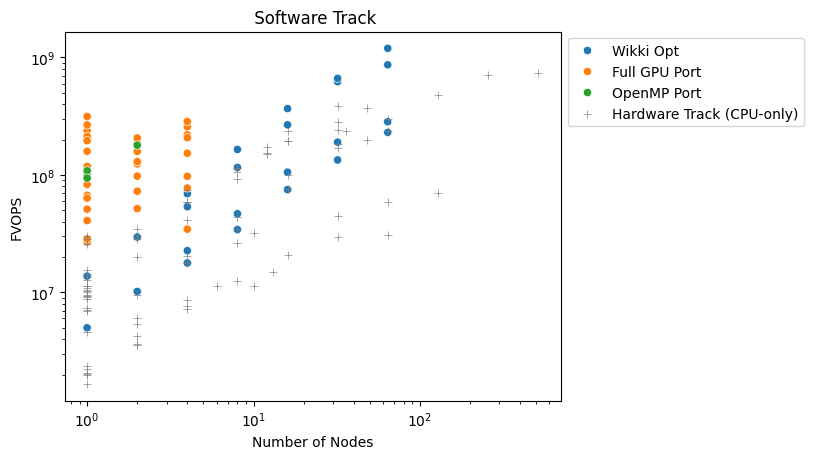

In [9]:
fig, ax = plt.subplots()
sb.scatterplot(df_software_ohc2,x="Number of Nodes", y="FVOPS", hue="Software Optimization Category", ax=ax)
sb.scatterplot(df_hardware_ohc2,x="Number of Nodes", y="FVOPS", label="Hardware Track (CPU-only)",color="gray", marker="+", ax=ax)
ax.set(xscale="log", yscale="log", title=" Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPS_Nodes_GPUOptimizationType", doSaveFig)

saving figure to figures_swtrack/FVOPS_Energy_OptimizationCat_OHC1.png


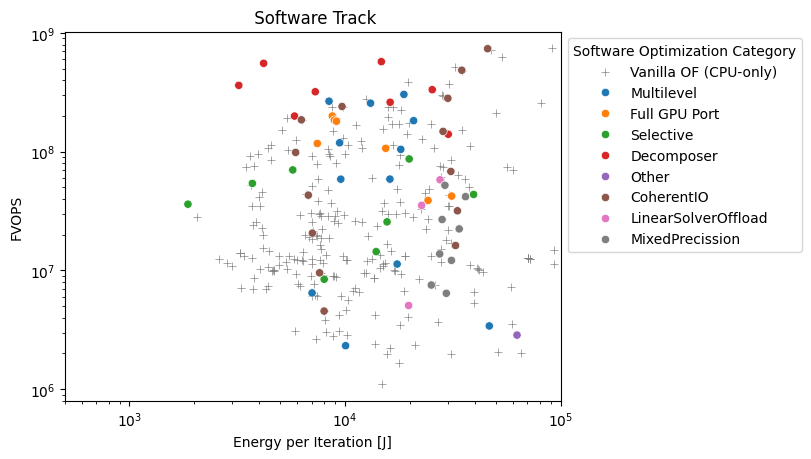

In [10]:
fig, ax = plt.subplots()
sb.scatterplot(df_hardware,x="Energy per Iteration [J]", y="FVOPS", color="gray", marker="+", label="Vanilla OF (CPU-only)", ax=ax)
sb.scatterplot(df_software_ohc1,x="Energy per Iteration [J]", y="FVOPS", hue="Software Optimization Category", ax=ax)
#ax = sb.scatterplot(df_software_ohc1,x="Energy per Iteration [J]", y="FVOPS", color="black", marker="o")
ax.set(xscale="log", yscale="log", title=" Software Track")
ax.set(xlim=(5e2,1e5))
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPS_Energy_OptimizationCat_OHC1", doSaveFig)

saving figure to figures_swtrack/FVOPS_Energy_OptimizationCat_OHC2.png


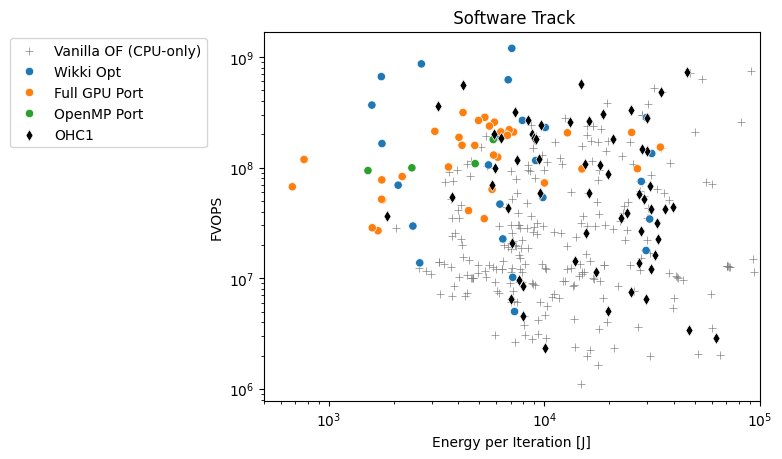

In [11]:
fig, ax = plt.subplots()
sb.scatterplot(df_hardware,x="Energy per Iteration [J]", y="FVOPS", color="gray", marker="+", label="Vanilla OF (CPU-only)", ax=ax)
sb.scatterplot(df_software_ohc2,x="Energy per Iteration [J]", y="FVOPS", hue="Software Optimization Category", ax=ax)
sb.scatterplot(df_software_ohc1,x="Energy per Iteration [J]", y="FVOPS", color="black", marker="d", label="OHC1", ax=ax)
ax.set(xscale="log", yscale="log", title=" Software Track")
ax.set(xlim=(5e2,1e5))

sb.move_legend(ax, "upper right", bbox_to_anchor=(-0.1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPS_Energy_OptimizationCat_OHC2", doSaveFig)

saving figure to figures_swtrack/FVOPS_EnergyPerIteration_FileName.png


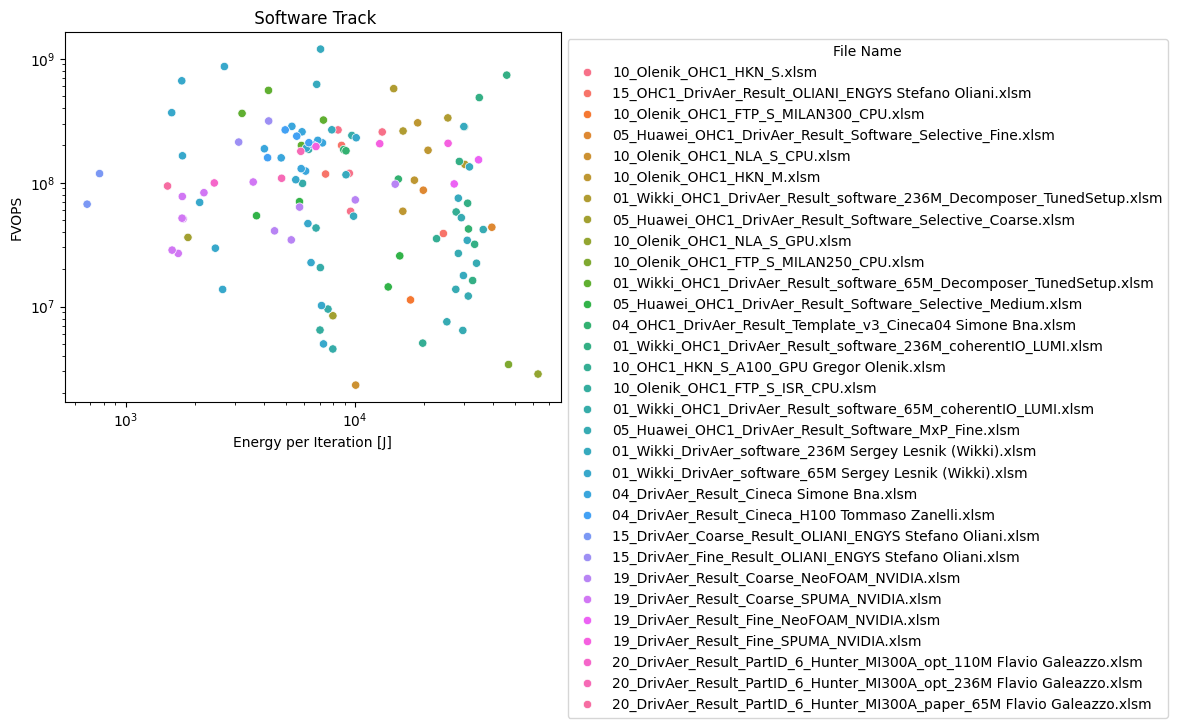

In [12]:
fig, ax = plt.subplots()
sb.scatterplot(df_software,x="Energy per Iteration [J]", y="FVOPS", hue="File Name", ax=ax)
ax.set(xscale="log", yscale="log", title=" Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPS_EnergyPerIteration_FileName", doSaveFig)

saving figure to figures_swtrack/FVOPS_EnergyPerIteration_withHWTrack.png


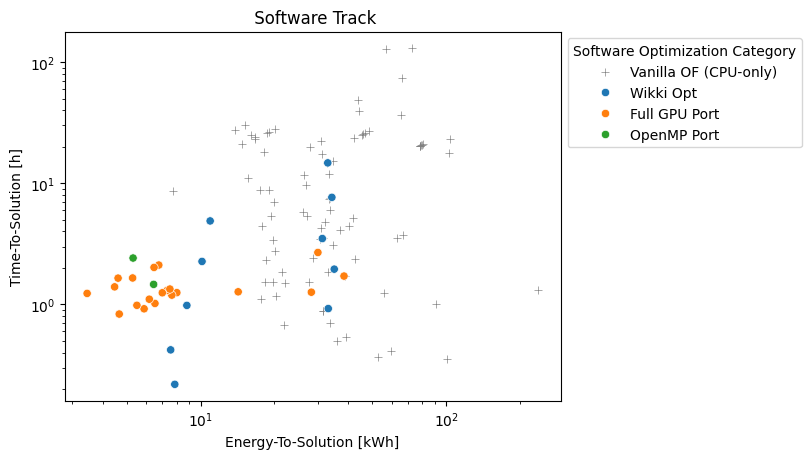

In [13]:
df_hardware_filt = df_hardware[df_hardware["Mesh"] == "fine"]
df_software_filt = df_software_ohc2[df_software_ohc2["Mesh"] == "fine"]

#df_software_filt = df_software_filt[
#    df_software_filt["Software Optimization Category"].isin(
#        ["Full GPU Port", "OpenMP Port"]
#    )]


fig, ax = plt.subplots()
sb.scatterplot(df_hardware_filt,x="Energy-To-Solution [kWh]", y="Time-To-Solution [h]", color="gray", marker="+", label="Vanilla OF (CPU-only)", ax=ax)
sb.scatterplot(df_software_filt,x="Energy-To-Solution [kWh]", y="Time-To-Solution [h]", hue="Software Optimization Category", ax=ax)
ax.set(xscale="log", yscale="log", title=" Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPS_EnergyPerIteration_withHWTrack", doSaveFig)

saving figure to figures_swtrack/TTS_ETS_softwareVsVanilla_byMesh.png


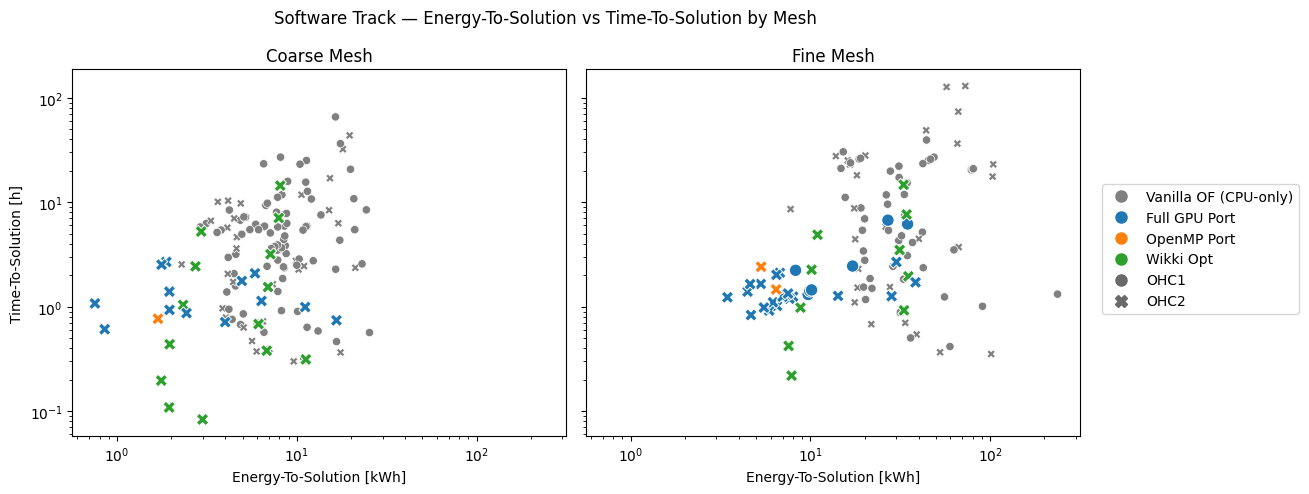

In [14]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Side-by-side version of the Energy-vs-Time software-vs-vanilla plot, one panel per mesh
meshes = ["coarse", "fine"]
cats = ["Full GPU Port", "OpenMP Port","Wikki Opt"]
palette = dict(zip(cats, sb.color_palette(n_colors=len(cats))))
markers = {"OHC1": "o", "OHC2": "X"}  # differentiate challenge by marker shape


def with_challenge(df):
    df = df.copy()
    df["Challenge"] = df["Edition"]
    return df


df_hardware_c = with_challenge(df_hardware)
df_software_c = with_challenge(df_software)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, mesh in zip(axes, meshes):
    df_hardware_filt = df_hardware_c[df_hardware_c["Mesh"] == mesh]
    df_software_filt = df_software_c[
        (df_software_c["Mesh"] == mesh)
        & (df_software_c["Software Optimization Category"].isin(cats))
    ]
    sb.scatterplot(df_hardware_filt, x="Energy-To-Solution [kWh]", y="Time-To-Solution [h]",
                   color="gray", style="Challenge", markers=markers, style_order=["OHC1", "OHC2"],
                   ax=ax, legend=False)
    sb.scatterplot(df_software_filt, x="Energy-To-Solution [kWh]", y="Time-To-Solution [h]",
                   hue="Software Optimization Category", hue_order=cats, palette=palette,
                   style="Challenge", markers=markers, style_order=["OHC1", "OHC2"],
                   s=80, ax=ax, legend=False)
    ax.set(xscale="log", yscale="log", title=f"{mesh.capitalize()} Mesh")
    ax.set_xlabel("Energy-To-Solution [kWh]")
    ax.set_ylabel("Time-To-Solution [h]" if ax is axes[0] else "")

handles = [Line2D([0], [0], marker="o", color="gray", linestyle="None", markersize=8,
                  label="Vanilla OF (CPU-only)")]
handles += [Line2D([0], [0], marker="o", color=palette[c], linestyle="None", markersize=8,
                   label=c) for c in cats]
handles += [Line2D([0], [0], marker=markers[ch], color="dimgray", linestyle="None", markersize=8,
                   label=ch) for ch in ["OHC1", "OHC2"]]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.suptitle("Software Track \u2014 Energy-To-Solution vs Time-To-Solution by Mesh")
fig.tight_layout()
op.save_fig(fig, fig_folder, "TTS_ETS_softwareVsVanilla_byMesh", doSaveFig)

saving figure to figures_swtrack/fvOpsW_cellsPerDevice_byMesh.png


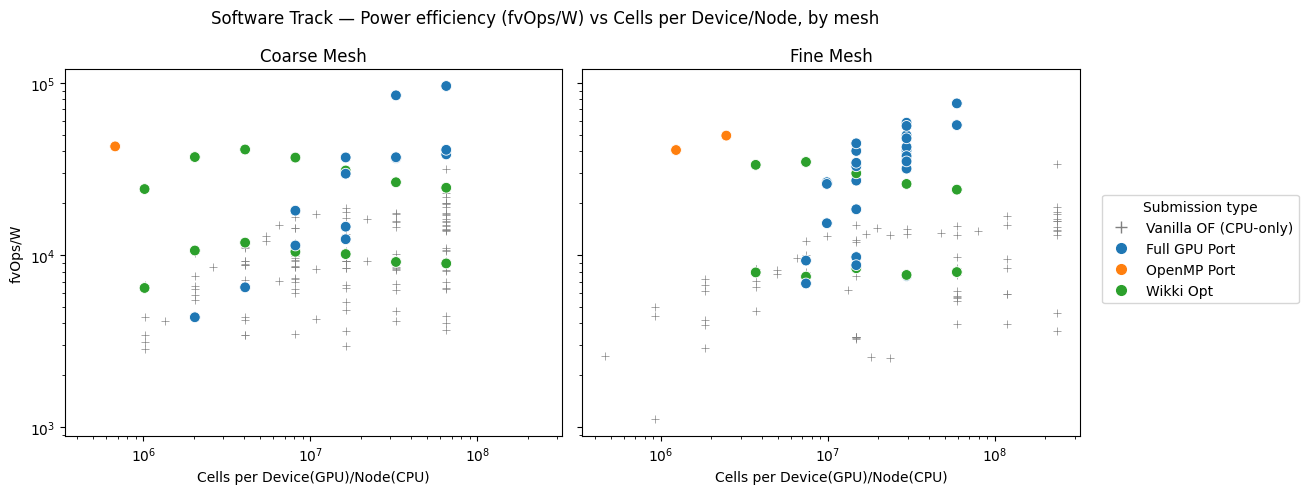

In [15]:
# Same side-by-side layout as above, but: y = fvOps/W (power efficiency), x = cells per device.
# "Device" = GPU when the run uses accelerators, else node (so the vanilla CPU reference still shows).
meshes = ["coarse", "fine"]
cats = ["Full GPU Port", "OpenMP Port", "Wikki Opt"]
palette = dict(zip(cats, sb.color_palette(n_colors=len(cats))))


def add_device_metrics(df):
    df = df.copy()
    gpu = pd.to_numeric(df["Number of GPU Devices"], errors="coerce")
    nodes = pd.to_numeric(df["Number of Nodes"], errors="coerce")
    devices = gpu.where(gpu > 0, nodes)
    df["Cells per Device"] = pd.to_numeric(df["Number of Cells"], errors="coerce") / devices
    df["fvOps/W"] = pd.to_numeric(df["FVOPS"], errors="coerce") / pd.to_numeric(df["System TDP [W]"], errors="coerce")
    return df


df_hardware_dev = add_device_metrics(df_hardware)
df_software_dev = add_device_metrics(df_software)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, mesh in zip(axes, meshes):
    df_hardware_filt = df_hardware_dev[df_hardware_dev["Mesh"] == mesh]
    df_software_filt = df_software_dev[
        (df_software_dev["Mesh"] == mesh)
        & (df_software_dev["Software Optimization Category"].isin(cats))
    ]
    sb.scatterplot(df_hardware_filt, x="Cells per Device", y="fvOps/W",
                   color="gray", marker="+", ax=ax, legend=False)
    sb.scatterplot(df_software_filt, x="Cells per Device", y="fvOps/W",
                   hue="Software Optimization Category", hue_order=cats,
                   palette=palette, s=60, ax=ax, legend=False)
    ax.set(xscale="log", yscale="log", title=f"{mesh.capitalize()} Mesh")
    ax.set_xlabel("Cells per Device(GPU)/Node(CPU)")
    ax.set_ylabel("fvOps/W" if ax is axes[0] else "")

handles = [Line2D([0], [0], marker="+", color="gray", linestyle="None", markersize=9,
                  label="Vanilla OF (CPU-only)")]
handles += [Line2D([0], [0], marker="o", color=palette[c], linestyle="None", markersize=7,
                   label=c) for c in cats]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), title="Submission type")
fig.suptitle("Software Track \u2014 Power efficiency (fvOps/W) vs Cells per Device/Node, by mesh")
fig.tight_layout()
op.save_fig(fig, fig_folder, "fvOpsW_cellsPerDevice_byMesh", doSaveFig)

saving figure to figures_swtrack/FVOPSEnergyPerIterationFine.png


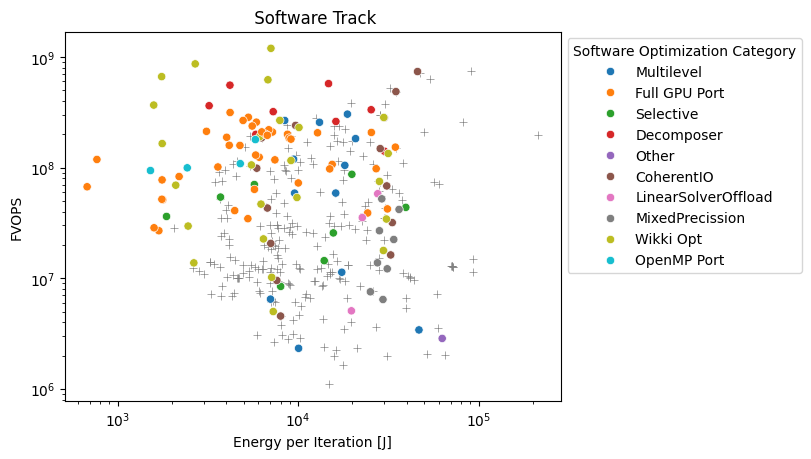

In [16]:
fig, ax = plt.subplots()
sb.scatterplot(df_hardware,x="Energy per Iteration [J]", y="FVOPS", color="gray", marker="+", ax=ax)
sb.scatterplot(df_software,x="Energy per Iteration [J]", y="FVOPS", hue="Software Optimization Category", ax=ax)
ax.set(xscale="log", yscale="log", title=" Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPSEnergyPerIterationFine", doSaveFig)

# Scaling

saving figure to figures_swtrack/wct_cores_GPUModel.png


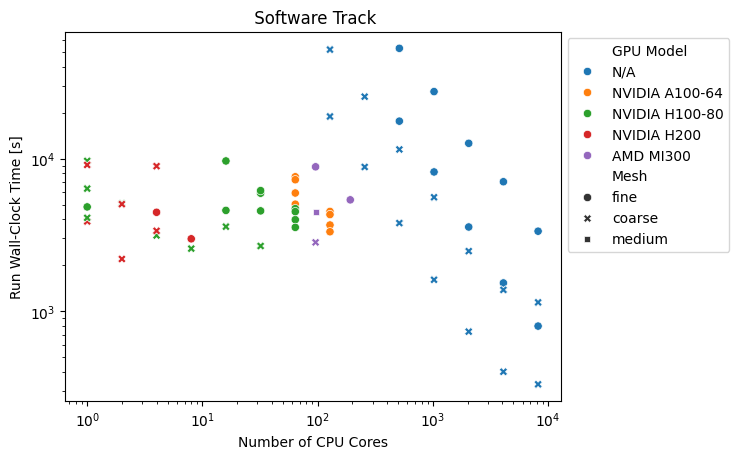

In [17]:
fig, ax = plt.subplots()
sb.scatterplot(df_software_ohc2,x="Number of CPU Cores", y="Run Wall-Clock Time [s]", hue="GPU Model", style="Mesh", ax=ax)
ax.set(xscale="log", yscale="log", title=" Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "wct_cores_GPUModel", doSaveFig)

saving figure to figures_swtrack/EnergyPerIteration_cores_GPUModel.png


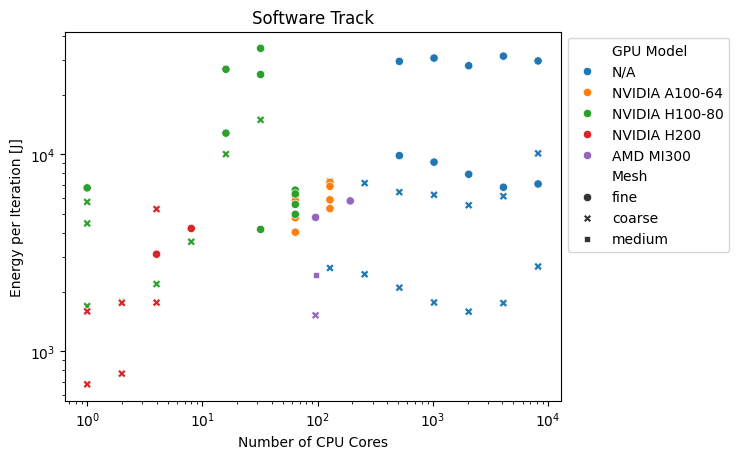

In [18]:
df_software_filt = df_software_ohc2
fig, ax = plt.subplots()
sb.scatterplot(df_software_filt,x="Number of CPU Cores", y="Energy per Iteration [J]", hue="GPU Model", style="Mesh", ax=ax)
ax.set(xscale="log", yscale="log", title="Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "EnergyPerIteration_cores_GPUModel", doSaveFig)

saving figure to figures_swtrack/TimePerIteration_cores_GPUModel.png


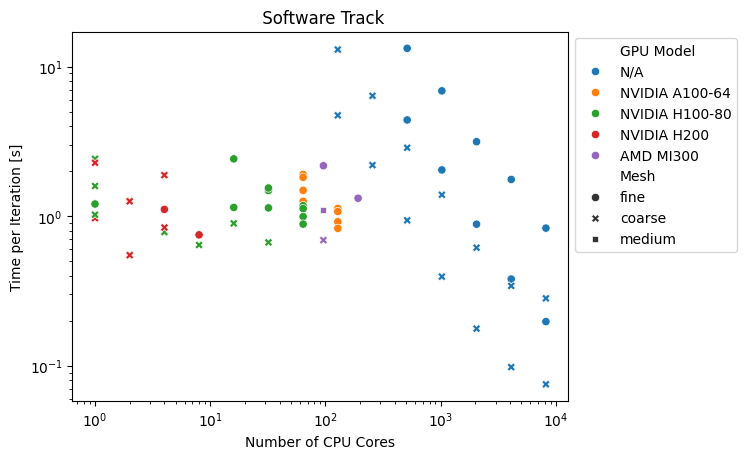

In [19]:
fig, ax = plt.subplots()
sb.scatterplot(df_software_ohc2,x="Number of CPU Cores", y="Time per Iteration [s]", hue="GPU Model", style="Mesh", ax=ax)
ax.set(xscale="log", yscale="log", title=" Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "TimePerIteration_cores_GPUModel", doSaveFig)

# Aerodynamic Coefficients

/var/folders/9k/fsqnnjlj7n10pwdjq41gzd340000gn/T/ipykernel_97004/3756776517.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(
/var/folders/9k/fsqnnjlj7n10pwdjq41gzd340000gn/T/ipykernel_97004/3756776517.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(
/var/folders/9k/fsqnnjlj7n10pwdjq41gzd340000gn/T/ipykernel_97004/3756776517.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(


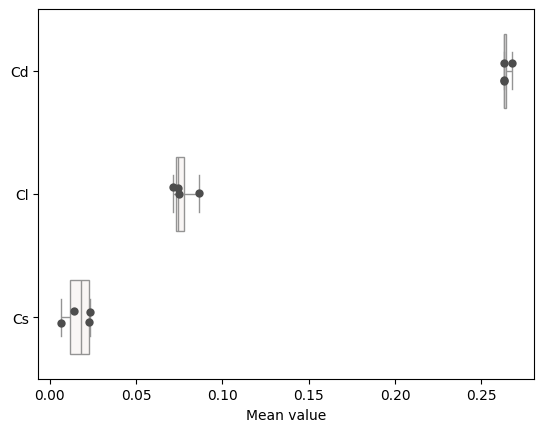

In [20]:
# only a few submissions filled the optional Meancalc table; keep those with means and
# one row per file (the means are repeated for every force sample)
dsfs_clean = dfsf.dropna(subset=["cd_mean", "cl_mean", "cs_mean"]).drop_duplicates("Filename").copy()
dsfs_clean = dsfs_clean[dsfs_clean["Contributor Affiliation"] != "CFD FEA SERVICE SRL"]
dsfs_clean["Cd mean"] = "Cd"
dsfs_clean["Cl mean"] = "Cl"
dsfs_clean["Cs mean"] = "Cs"

fig, ax = plt.subplots()
sb.boxplot(
    dsfs_clean, x="cd_mean", y="Cd mean",
    whis=[0, 100], width=.6, palette="vlag", ax=ax
)
sb.boxplot(
    dsfs_clean, x="cl_mean", y="Cl mean",
    whis=[0, 100], width=.6, palette="vlag", ax=ax
)
sb.boxplot(
    dsfs_clean, x="cs_mean", y="Cs mean",
    whis=[0, 100], width=.6, palette="vlag", ax=ax
)
sb.stripplot(dsfs_clean, x="cd_mean", y="Cd mean", size=6, color=".3", ax=ax)
sb.stripplot(dsfs_clean, x="cl_mean", y="Cl mean", size=6, color=".3", ax=ax)
sb.stripplot(dsfs_clean, x="cs_mean", y="Cs mean", size=6, color=".3", ax=ax)

ax.set(xlabel='Mean value', ylabel='')

fig = ax.get_figure()

/var/folders/9k/fsqnnjlj7n10pwdjq41gzd340000gn/T/ipykernel_97004/501984831.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(


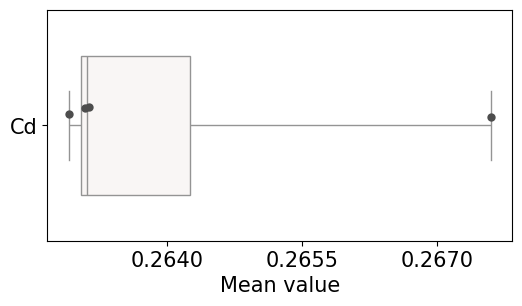

In [21]:

fig, ax = plt.subplots()
sb.boxplot(
    dsfs_clean, x="cd_mean", y="Cd mean",
    whis=[0, 100], width=.6, palette="vlag", ax=ax
)
sb.stripplot(dsfs_clean, x="cd_mean", y="Cd mean", size=6, color=".3", ax=ax)

ax.set_xlabel('Mean value', fontsize=15)
ax.set_ylabel('')
ax.tick_params(labelsize=15)
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.4f"))

fig = ax.get_figure()
fig.set_size_inches(6, 3)

/var/folders/9k/fsqnnjlj7n10pwdjq41gzd340000gn/T/ipykernel_97004/4281223145.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(


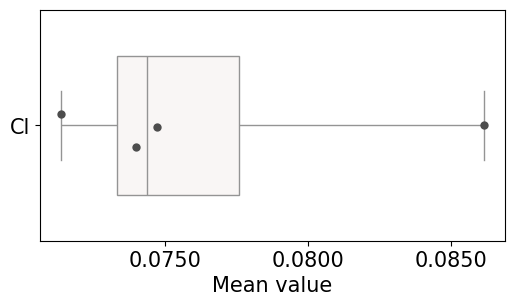

In [22]:
fig, ax = plt.subplots()
sb.boxplot(
    dsfs_clean, x="cl_mean", y="Cl mean",
    whis=[0, 100], width=.6, palette="vlag",
    ax=ax,
)
sb.stripplot(dsfs_clean, x="cl_mean", y="Cl mean", size=6, color=".3", ax=ax)

ax.set_xlabel('Mean value', fontsize=15)
ax.set_ylabel('')
ax.tick_params(labelsize=15)
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.4f"))

fig = ax.get_figure()
fig.set_size_inches(6, 3)

/var/folders/9k/fsqnnjlj7n10pwdjq41gzd340000gn/T/ipykernel_97004/3104604644.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(


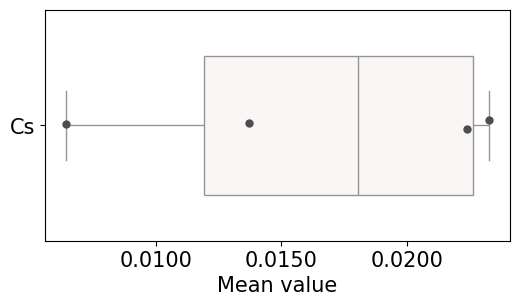

In [23]:
fig, ax = plt.subplots()
sb.boxplot(
    dsfs_clean, x="cs_mean", y="Cs mean",
    whis=[0, 100], width=.6, palette="vlag", ax=ax
)
sb.stripplot(dsfs_clean, x="cs_mean", y="Cs mean", size=6, color=".3", ax=ax)

ax.set_xlabel('Mean value', fontsize=15)
ax.set_ylabel('')
ax.tick_params(labelsize=15)
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.4f"))

fig = ax.get_figure()
fig.set_size_inches(6, 3)

saving figure to figures_swtrack/gpu_port_strong_scaling.png


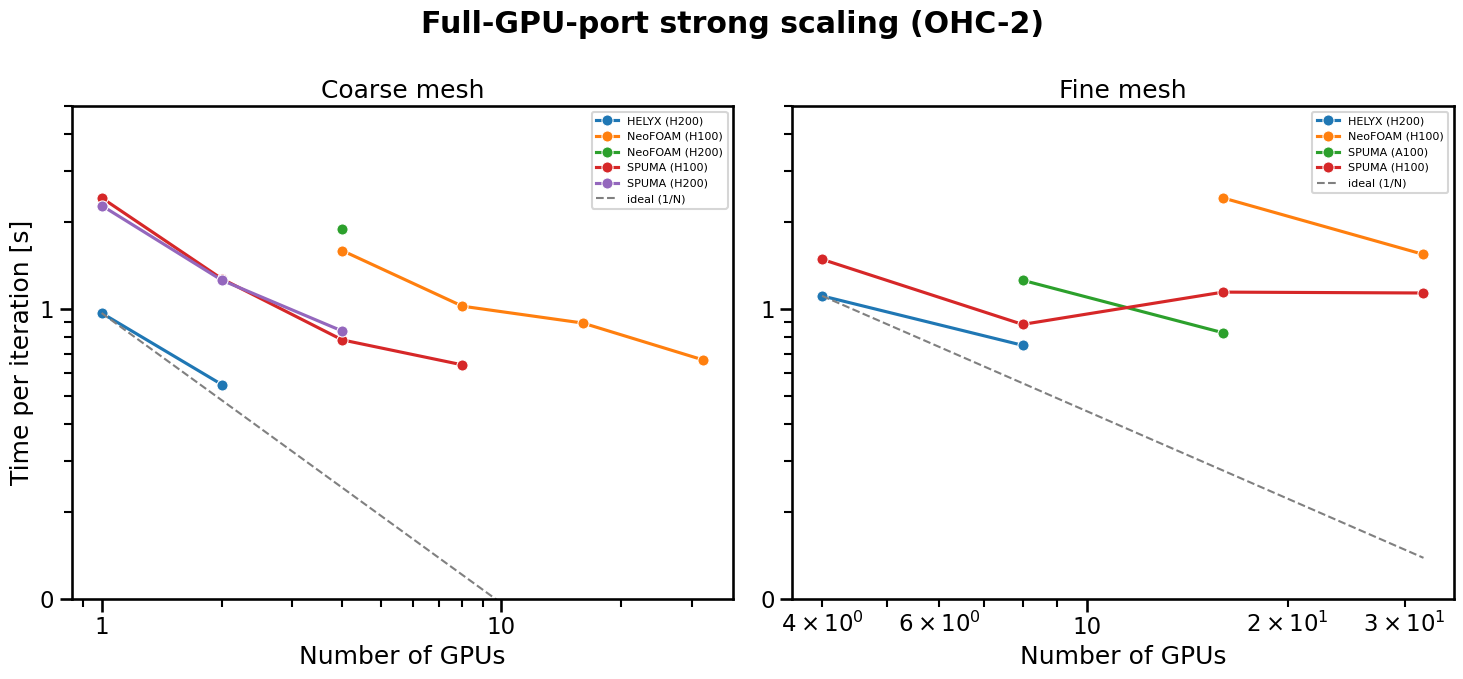

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

# Full-GPU-port multi-GPU strong scaling: time per iteration vs number of GPUs, per mesh.
gp = dfs[(dfs["Software Optimization Category"] == "Full GPU Port")
         & (dfs["Edition"] == "OHC2")].copy()
gp["GPUn"] = pd.to_numeric(gp["Number of GPU Devices"], errors="coerce")
gp["tpi"] = pd.to_numeric(gp["Time per Iteration [s]"], errors="coerce")
gp = gp.dropna(subset=["GPUn", "tpi"])
gp = gp[gp["GPUn"] > 0]


def solver_name(fn):
    l = fn.lower()
    if "spuma" in l:
        return "SPUMA"
    if "neofoam" in l:
        return "NeoFOAM"
    if "engys" in l or "oliani" in l:
        return "HELYX"
    if "cineca" in l:
        return "SPUMA"  # CINECA submissions run the SPUMA code
    return "GPU port"


def gpu_short(g):
    return g.replace("NVIDIA ", "").replace("-80", "").replace("-64", "")


gp["Series"] = [f"{solver_name(f)} ({gpu_short(g)})" for f, g in zip(gp["File Name"], gp["GPU Model"])]
# best (min) time per (series, mesh, GPU count)
agg = gp.groupby(["Series", "Mesh", "GPUn"], as_index=False)["tpi"].min()

with sb.plotting_context("talk"):
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    for ax, mesh in zip(axes, ["coarse", "fine"]):
        d = agg[agg["Mesh"] == mesh].sort_values(["Series", "GPUn"])
        sb.lineplot(d, x="GPUn", y="tpi", hue="Series", marker="o", markersize=8, ax=ax)
        if len(d):  # ideal 1/N guide, anchored at the fastest series' smallest-GPU point
            base = d.loc[d["GPUn"].idxmin()]
            xs = np.array(sorted(d["GPUn"].unique()))
            ax.plot(xs, base["tpi"] * base["GPUn"] / xs, ls="--", color="gray", lw=1.5, label="ideal (1/N)")
        ax.set(xscale="log", yscale="log", title=f"{mesh.capitalize()} mesh")
        ax.set(ylim=(0.1, 5))
        #ax.set(xlim=(0.5, 50))
        ax.set_xlabel("Number of GPUs")
        ax.set_ylabel("Time per iteration [s]" if ax is axes[0] else "")
        ax.xaxis.set_major_formatter(FormatStrFormatter("%d"))
        ax.yaxis.set_major_formatter(FormatStrFormatter("%d"))
        ax.legend(fontsize=8)
    fig.suptitle("Full-GPU-port strong scaling (OHC-2)", fontweight="bold")
    fig.tight_layout()
    op.save_fig(fig, fig_folder, "gpu_port_strong_scaling", doSaveFig)

saving figure to figures_swtrack/openmp_vs_fullgpu_efficiency.png


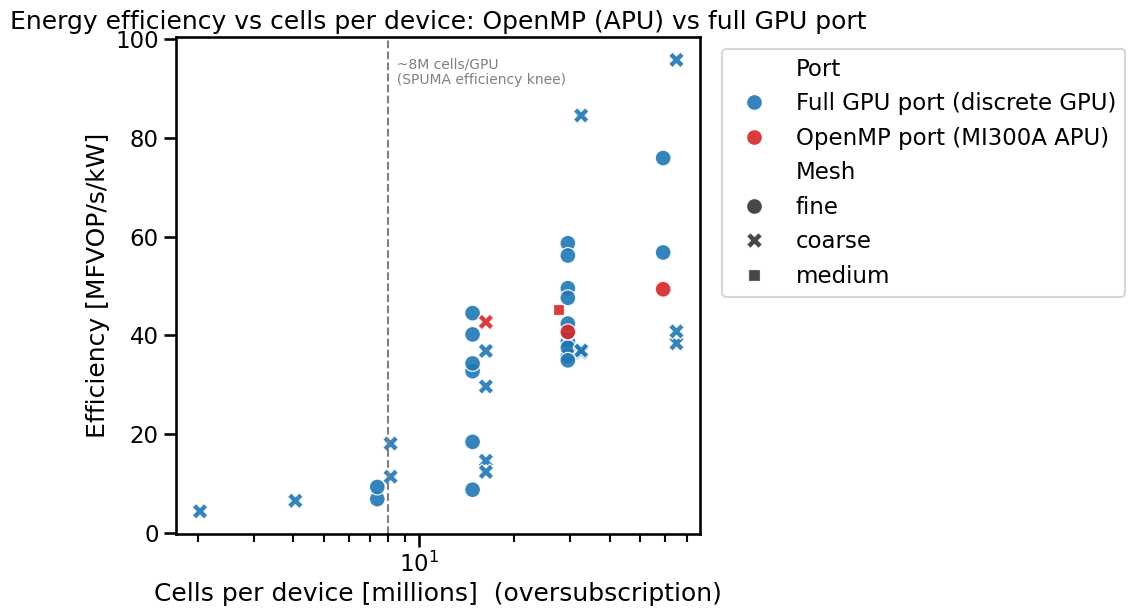

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# OpenMP port (AMD MI300A APU, OpenMP offload + unified memory) vs Full GPU port (SPUMA / HELYX /
# NeoFOAM on discrete GPUs). Both papers show efficiency is governed by cells-per-device
# (oversubscription):
#   - SPUMA (Bna et al., arXiv:2512.22215): ~65% strong-scaling efficiency near ~8M cells/GPU,
#     up to 82% energy saving vs CPU.
#   - MI300A OpenMP offload (Saurabh & Grinberg, AMD): unified-memory APU, minimal code changes.
d = dfs[dfs["Software Optimization Category"].isin(["OpenMP Port", "Full GPU Port"])].copy()
d = d[d["Edition"] == "OHC2"]
d["eff"] = (pd.to_numeric(d["FVOPS"], errors="coerce") / 1e6) / (pd.to_numeric(d["System TDP [W]"], errors="coerce") / 1000.0)
d["nodes"] = pd.to_numeric(d["Number of Nodes"], errors="coerce")
d["gpun"] = pd.to_numeric(d["Number of GPU Devices"], errors="coerce")
# device count: full-GPU-port = number of GPUs; MI300A OpenMP = 4 APUs per node
d["ndev"] = np.where(d["Software Optimization Category"] == "OpenMP Port", d["nodes"] * 4, d["gpun"])
d["cells_per_dev_M"] = pd.to_numeric(d["Number of Cells"], errors="coerce") / d["ndev"] / 1e6
d["Port"] = np.where(d["Software Optimization Category"] == "OpenMP Port",
                     "OpenMP port (MI300A APU)", "Full GPU port (discrete GPU)")
d = d.dropna(subset=["eff", "cells_per_dev_M"])
d = d[(d["eff"] > 0) & (d["cells_per_dev_M"] > 0)]

with sb.plotting_context("talk"):
    fig, ax = plt.subplots(figsize=(11, 6.5))
    sb.scatterplot(d, x="cells_per_dev_M", y="eff", hue="Port", style="Mesh", s=130, alpha=0.9, ax=ax,
                   palette={"OpenMP port (MI300A APU)": "#d62728",
                            "Full GPU port (discrete GPU)": "#1f77b4"})
    ax.axvline(8, ls="--", color="gray", lw=1.5)
    ax.text(8, ax.get_ylim()[1] * 0.96, "  ~8M cells/GPU\n  (SPUMA efficiency knee)",
            fontsize=10, color="gray", va="top")
    ax.set(xscale="log", title="Energy efficiency vs cells per device: OpenMP (APU) vs full GPU port")
    ax.set_xlabel("Cells per device [millions]  (oversubscription)")
    ax.set_ylabel("Efficiency [MFVOP/s/kW]")
    sb.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1))
    fig.tight_layout()
    op.save_fig(fig, fig_folder, "openmp_vs_fullgpu_efficiency", doSaveFig)

saving figure to figures_swtrack/spdp_vs_dp_spuma.png


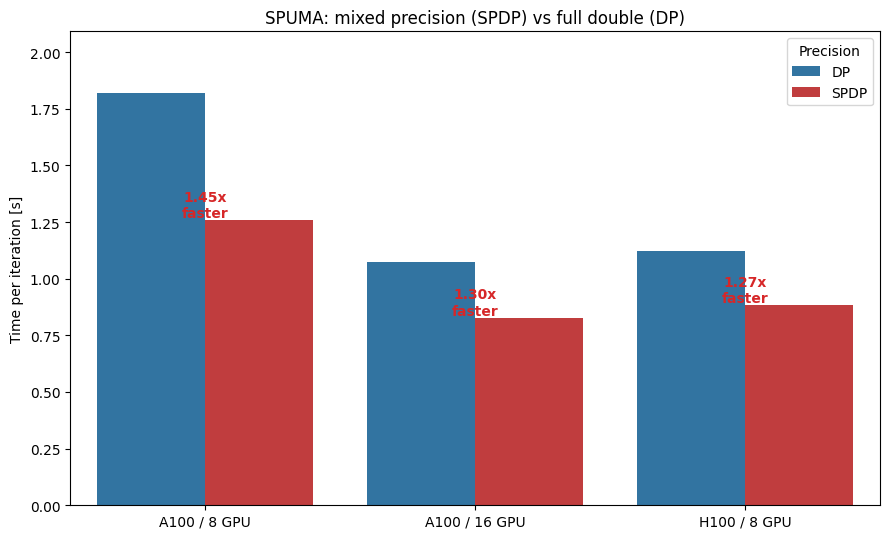

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# SPDP (mixed single/double precision) vs DP (full double) on the SAME code (SPUMA / CINECA).
# Precision is recorded per run in the submission sheet ("Double precision (DP)" / "Mixed Precision (SPDP)").
prec_files = {"04_DrivAer_Result_Cineca Simone Bna.xlsm": "A100",
              "04_DrivAer_Result_Cineca_H100 Tommaso Zanelli.xlsm": "H100"}


def _find_row(raw, pattern):
    for r in range(len(raw)):
        if raw.iloc[r].astype(str).str.contains(pattern, case=False, na=False, regex=True).any():
            return r
    return None


prec_rows = []
for fn, gpu in prec_files.items():
    raw = pd.read_excel(os.path.join("submissions", fn), sheet_name="Simulations", header=None)
    rt = _find_row(raw, r"Wall-clock time per timestep")
    rg = _find_row(raw, r"# of GPUs used")
    rp = _find_row(raw, r"SPDP|Double precision")
    for ti, gi, pi in zip(raw.iloc[rt, 3:12], raw.iloc[rg, 3:12], raw.iloc[rp, 3:12]):
        if pd.isna(ti) or pd.isna(gi):
            continue
        prec = "SPDP" if "SPDP" in str(pi) else ("DP" if "Double" in str(pi) else None)
        if prec:
            prec_rows.append({"GPU": gpu, "GPUs": int(gi), "Precision": prec, "tpi": float(ti)})

prec_df = pd.DataFrame(prec_rows)
prec_df["cfg"] = prec_df["GPU"] + " / " + prec_df["GPUs"].astype(str) + " GPU"
# keep only configurations that have BOTH precisions (fair paired comparison)
paired = prec_df.groupby("cfg")["Precision"].nunique()
prec_df = prec_df[prec_df["cfg"].isin(paired[paired == 2].index)]

best = prec_df.groupby(["cfg", "Precision"])["tpi"].min().unstack("Precision")
order = sorted(best.index, key=lambda s: (s.split()[0], int(s.split("/")[1].split()[0])))

fig, ax = plt.subplots(figsize=(9, 5.5))
sb.barplot(prec_df, x="cfg", y="tpi", hue="Precision", order=order, hue_order=["DP", "SPDP"],
           estimator="min", errorbar=None, palette={"DP": "#1f77b4", "SPDP": "#d62728"}, ax=ax)
for i, cfg in enumerate(order):  # annotate SPDP speedup over DP
    sp = best.loc[cfg, "DP"] / best.loc[cfg, "SPDP"]
    ax.text(i, best.loc[cfg, "SPDP"], f"{sp:.2f}x\nfaster", ha="center", va="bottom",
            fontsize=10, fontweight="bold", color="#d62728")
ax.set(title="SPUMA: mixed precision (SPDP) vs full double (DP)", ylabel="Time per iteration [s]", xlabel="")
ax.margins(y=0.15)
fig.tight_layout()
op.save_fig(fig, fig_folder, "spdp_vs_dp_spuma", doSaveFig)